In [2]:
# Import thư viện cơ bản
import pandas as pd
import numpy as np

# Cấu hình hiển thị: hiện đủ cột, không rút gọn
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

In [3]:
# Đọc 2 file CSV từ thư mục data/ (notebook ở notebooks/ → lùi 1 cấp)
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
# In shape để xác nhận đọc đúng
print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (891, 12)
Test shape: (418, 11)


In [4]:
# Xem 5 dòng đầu
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Kiểu dữ liệu + số giá trị non-null
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Thống kê mô tả cho các cột số
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Đếm số lượng + tỷ lệ missing của từng cột (cả train và test)
for name, df in [('TRAIN', train), ('TEST', test)]:
    miss = df.isnull().sum()
    pct  = (miss / len(df) * 100).round(2)
    result = pd.DataFrame({'missing': miss, 'percent': pct})
    result = result[result['missing'] > 0].sort_values('missing', ascending=False)
    print(f'=== {name} ===')
    print(result if len(result) else 'Không có missing')
    print()

=== TRAIN ===
          missing  percent
Cabin         687    77.10
Age           177    19.87
Embarked        2     0.22

=== TEST ===
       missing  percent
Cabin      327    78.23
Age         86    20.57
Fare         1     0.24



## Nhận xét missing values

**Train:**
- Cabin: 687 (77.10%) — quá nhiều, sẽ bỏ cột ở Bước 3, tạo HasCabin ở Bước 4.
- Age: 177 (19.87%) — sẽ fill median ở Bước 3.
- Embarked: 2 (0.22%) — sẽ fill mode ở Bước 3.

**Test:**
- Cabin: 327 (78.23%) — cùng cách xử lý như train.
- Age: 86 (20.57%) — cùng median của train (không tính lại median trên test → tránh data leakage).
- Fare: 1 (0.24%) — test thiếu nhưng train không thiếu → fill bằng median train khi predict.

**Nguyên tắc chung:**
- Mọi phép biến đổi (fill, encode, scale) fit trên train, áp dụng cho test.
- Sẽ đóng gói trong Pipeline ở Bước 3.

In [8]:
# Import thư viện vẽ
import matplotlib.pyplot as plt
import seaborn as sns

# Style: nền trắng, font rõ
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Màu cho 2 lớp target: 0 = đỏ (chết), 1 = xanh (sống)
palette = {0: '#e74c3c', 1:'#2ecc71'}


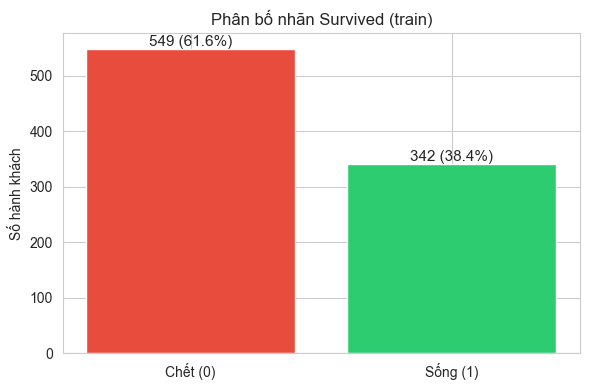

In [9]:
# Đếm số lượng mỗi lớp
counts = train['Survived'].value_counts().sort_index()

# Vẽ bar chart
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Chết (0)', 'Sống (1)'], counts.values, color=[palette[0], palette[1]])

# Ghi số + % ngay trên mỗi cột
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val +5,
            f'{val} ({val/len(train)*100:.1f}%)',
                ha='center', fontsize=11)

ax.set_title('Phân bố nhãn Survived (train)')
ax.set_ylabel('Số hành khách')
plt.tight_layout()
plt.savefig('../reports/figures/01_survived_dist.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_32976\1785999217.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x='Sex', y='Survived',


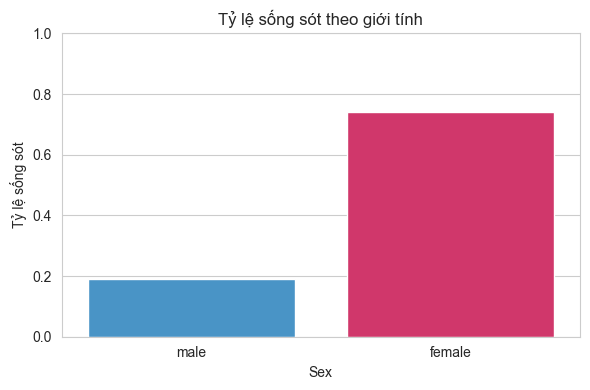

In [10]:
# Tỷ lệ sống sót theo giới tính
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=train, x='Sex', y='Survived',
            palette={'male': '#3498db', 'female': '#e91e63'},
            ax=ax, errorbar=None)

ax.set_title('Tỷ lệ sống sót theo giới tính')
ax.set_ylabel('Tỷ lệ sống sót')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../reports/figures/02_survived_by_sex.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_32976\2707961112.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x='Pclass', y='Survived',


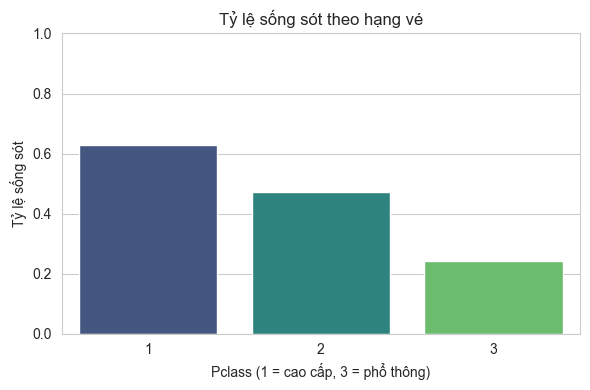

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=train, x='Pclass', y='Survived',
            palette='viridis', ax=ax, errorbar=None)

ax.set_title('Tỷ lệ sống sót theo hạng vé')
ax.set_xlabel('Pclass (1 = cao cấp, 3 = phổ thông)')
ax.set_ylabel('Tỷ lệ sống sót')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../reports/figures/03_survived_by_pclass.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_32976\1326033627.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x='Embarked', y='Survived',


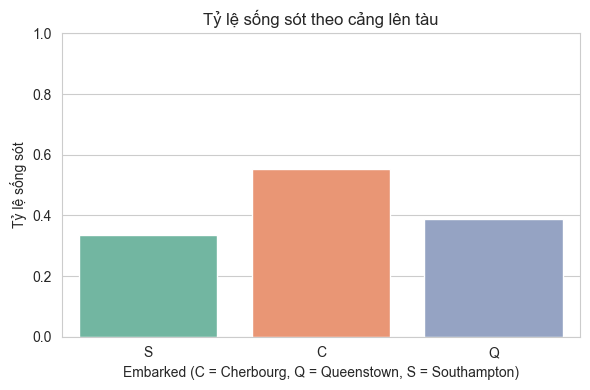

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=train, x='Embarked', y='Survived',
            palette='Set2', ax=ax, errorbar=None)

ax.set_title('Tỷ lệ sống sót theo cảng lên tàu')
ax.set_xlabel('Embarked (C = Cherbourg, Q = Queenstown, S = Southampton)')
ax.set_ylabel('Tỷ lệ sống sót')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../reports/figures/04_survived_by_embarked.png', dpi=100, bbox_inches='tight')
plt.show()

In [13]:
# Bảng tỷ lệ sống sót chính xác theo từng biến
for col in ['Sex', 'Pclass', 'Embarked']:
    print(f'=== {col} ===')
    print(train.groupby(col)['Survived'].agg(['count', 'mean']).round(3))
    print()

=== Sex ===
        count   mean
Sex                 
female    314  0.742
male      577  0.189

=== Pclass ===
        count   mean
Pclass              
1         216  0.630
2         184  0.473
3         491  0.242

=== Embarked ===
          count   mean
Embarked              
C           168  0.554
Q            77  0.390
S           644  0.337



## Nhận xét Khối 2.3

**Survived:** 549 chết (61.6%) / 342 sống (38.4%) — mất cân bằng nhẹ.

**Sex — feature MẠNH NHẤT:**
- female: 314 người, tỷ lệ sống 74.2%
- male: 577 người, tỷ lệ sống 18.9%
- Chênh ~3.9x → encode binary, giữ làm feature chính.

**Pclass — feature mạnh thứ 2:**
- Hạng 1: 216 người, 63.0%
- Hạng 2: 184 người, 47.3%
- Hạng 3: 491 người, 24.2%
- Xu hướng giảm dần 1→2→3, chênh ~2.6x → giữ nguyên dạng số.

**Embarked — feature yếu:**
- C: 168 người, 55.4%
- Q: 77 người, 39.0%
- S: 644 người, 33.7%
- Chênh ~1.6x → có thể giữ (one-hot) hoặc bỏ, thử ở Bước 5.

**Kiểm tra count:** mọi nhóm đều >= 77 người → số liệu đáng tin, không có nhóm quá nhỏ.

**Kết luận:** Sex + Pclass là 2 feature then chốt. Embarked giữ làm feature phụ.

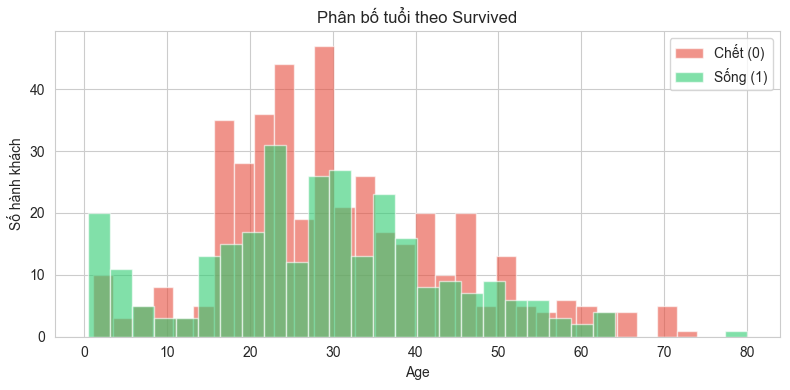

In [14]:
# Histogram Age, chia màu theo Survived
fig, ax = plt.subplots(figsize=(8, 4))

# Vẽ 2 histogram chồng lên nhau (survived=0 và =1)
train[train['Survived'] == 0]['Age'].plot(
    kind='hist', bins=30, alpha=0.6, color=palette[0],
    label='Chết (0)', ax=ax)
train[train['Survived'] == 1]['Age'].plot(
    kind='hist', bins=30, alpha=0.6, color=palette[1],
    label='Sống (1)', ax=ax)

ax.set_title('Phân bố tuổi theo Survived')
ax.set_xlabel('Age')
ax.set_ylabel('Số hành khách')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/05_age_dist.png', dpi=100, bbox_inches='tight')
plt.show()

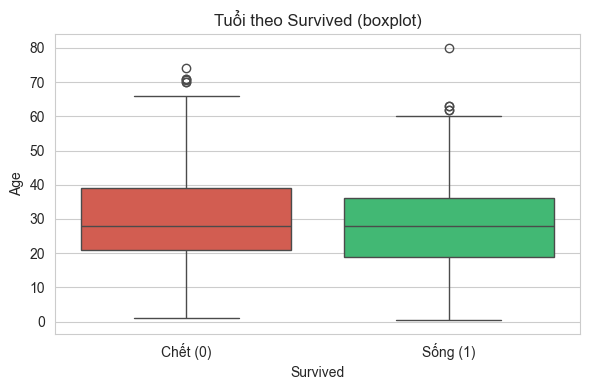

In [15]:
# Boxplot: tuổi theo nhóm sống/chết
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=train, x='Survived', y='Age',
            hue='Survived', palette=[palette[0], palette[1]],
            legend=False, ax=ax)

ax.set_title('Tuổi theo Survived (boxplot)')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Chết (0)', 'Sống (1)'])
plt.tight_layout()
plt.savefig('../reports/figures/06_age_boxplot.png', dpi=100, bbox_inches='tight')
plt.show()

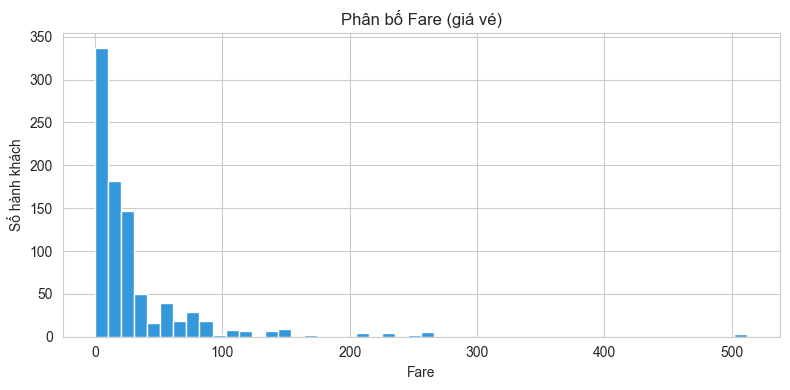

In [16]:
# Histogram Fare — riêng, vì lệch nặng
fig, ax = plt.subplots(figsize=(8, 4))
train['Fare'].plot(kind='hist', bins=50, color='#3498db', ax=ax)

ax.set_title('Phân bố Fare (giá vé)')
ax.set_xlabel('Fare')
ax.set_ylabel('Số hành khách')
plt.tight_layout()
plt.savefig('../reports/figures/07_fare_dist.png', dpi=100, bbox_inches='tight')
plt.show()

In [17]:
# Tính IQR để phát hiện outlier cho Fare
Q1 = train['Fare'].quantile(0.25)
Q3 = train['Fare'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = train[(train['Fare'] < lower) | (train['Fare'] > upper)]

print(f'Q1 = {Q1:.2f}')
print(f'Q3 = {Q3:.2f}')
print(f'IQR = {IQR:.2f}')
print(f'Ngưỡng outlier: < {lower:.2f} hoặc > {upper:.2f}')
print(f'Số outlier: {len(outliers)} ({len(outliers)/len(train)*100:.1f}%)')
print(f'Max Fare: {train["Fare"].max():.2f}')

Q1 = 7.91
Q3 = 31.00
IQR = 23.09
Ngưỡng outlier: < -26.72 hoặc > 65.63
Số outlier: 116 (13.0%)
Max Fare: 512.33


C:\Users\ASUS\AppData\Local\Temp\ipykernel_32976\454529927.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x=col, y='Survived',
C:\Users\ASUS\AppData\Local\Temp\ipykernel_32976\454529927.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x=col, y='Survived',


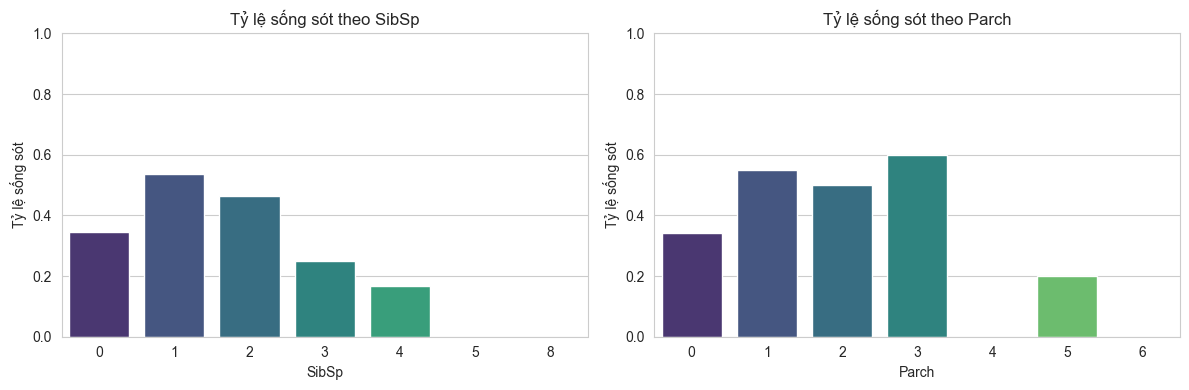

In [18]:
# Tỷ lệ sống sót theo SibSp và Parch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ['SibSp', 'Parch']):
    sns.barplot(data=train, x=col, y='Survived',
                palette='viridis', ax=ax, errorbar=None)
    ax.set_title(f'Tỷ lệ sống sót theo {col}')
    ax.set_ylabel('Tỷ lệ sống sót')
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('../reports/figures/08_sibsp_parch.png', dpi=100, bbox_inches='tight')
plt.show()

## Nhận xét Khối 2.4

**Age:**
- Median 2 nhóm gần bằng nhau (~27) → Age một mình tách target yếu.
- Nhóm sống có Q1 thấp hơn (~19 vs ~21) → trẻ em sống nhiều hơn.
- Outlier: cụ 80 tuổi vẫn sống sót.
- Missing 20% → Bước 3 fill median.
- Bước 4 tạo IsChild = Age < 10.

**Fare:**
- Lệch RẤT nặng: đa số < 50, max 512.33.
- Q1 = 7.91, Q3 = 31.00, IQR = 23.09.
- Ngưỡng outlier > 65.63 → 116 outlier (13.0%).
- Bước 4 cân nhắc log-transform (cho LR), giữ nguyên (cho tree model).

**SibSp / Parch:**
- Phi tuyến rõ: giá trị 1-3 có tỷ lệ sống cao nhất.
- 0 (đi một mình) và > 4 (gia đình quá đông) đều thấp.
- Cảnh báo: SibSp=5,8 và Parch=4,6 có rất ít người → không kết luận mạnh.
- Bước 4 gộp thành FamilySize = SibSp + Parch + 1.

In [19]:
# Chỉ tính tương quan trên cột số (bỏ Name, Sex, Ticket, Cabin, Embarked)
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

corr = train[numeric_cols].corr(numeric_only=True)

print('Hệ số tương quan với Survived (sắp giảm dần):')
print(corr['Survived'].sort_values(ascending=False).round(3))

Hệ số tương quan với Survived (sắp giảm dần):
Survived    1.000
Fare        0.257
Parch       0.082
SibSp      -0.035
Age        -0.077
Pclass     -0.338
Name: Survived, dtype: float64


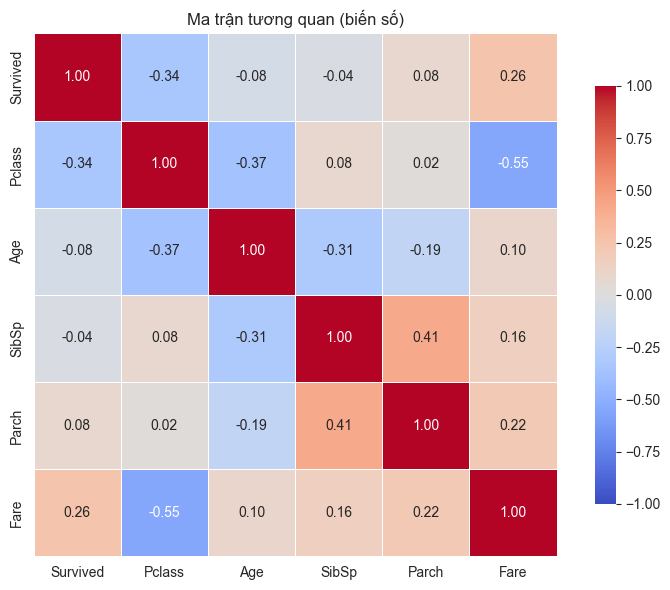

In [20]:
# Vẽ heatmap ma trận tương quan
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr,
            annot=True,        # in số trên ô
            fmt='.2f',         # 2 chữ số thập phân
            cmap='coolwarm',   # xanh dương (âm) → đỏ (dương)
            center=0,          # màu trắng ở giữa (r=0)
            vmin=-1, vmax=1,   # scale cố định
            square=True,       # ô vuông
            linewidths=0.5,    # đường phân cách
            cbar_kws={'shrink': 0.8},
            ax=ax)

ax.set_title('Ma trận tương quan (biến số)')
plt.tight_layout()
plt.savefig('../reports/figures/09_corr_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

In [21]:
# Đa cộng tuyến: cặp feature tương quan mạnh với nhau (|r| > 0.5)
corr_matrix = train[numeric_cols].corr(numeric_only=True).abs()

# Lấy nửa trên của ma trận (tránh trùng lặp)
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Các cặp có |r| > 0.5
high_corr = [(col, row, upper.loc[row, col])
             for col in upper.columns
             for row in upper.index
             if upper.loc[row, col] > 0.5]

print('Cặp feature tương quan mạnh (|r| > 0.5):')
for c1, c2, r in high_corr:
    print(f'  {c1} ↔ {c2}: {r:.3f}')

Cặp feature tương quan mạnh (|r| > 0.5):
  Fare ↔ Pclass: 0.549


## Nhận xét Khối 2.5 — Tương quan

**Tương quan với Survived (Pearson):**
- Pclass: ~ -0.34 (mạnh nhất trong cột số)
- Fare: ~ 0.26
- Parch: ~ 0.08
- SibSp: ~ -0.04
- Age: ~ -0.07

**Cảnh báo:** Sex (feature mạnh nhất) KHÔNG xuất hiện vì là chuỗi.
Sau khi encode ở Bước 3, cần kiểm tra lại.

**Đa cộng tuyến:**
- Pclass ↔ Fare: ~ -0.55 — cặp duy nhất |r| > 0.5.
- Đây là vấn đề NHẸ — vẫn giữ cả 2 vì đều tương quan với target.

**Hạn chế của Pearson:**
- Không bắt được phi tuyến (SibSp, Parch đã thấy phi tuyến ở Khối 2.4).
- Không dùng được cho feature categorical (Sex, Embarked).

**Kết luận:** 
- Cần encode Sex ở Bước 3 để đo tương quan thật.
- Feature quan trọng dự kiến: Sex > Pclass > Fare > Age.